Comp 541 - Group Project

Fake News Detection Data Mining Project

EDA & Data Cleaning

Load the necessary libraries:

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import string

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import PassiveAggressiveClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

Loading the datasets and add labels for real/fake news:

In [2]:
fake_df = pd.read_csv("Fake.csv")
real_df = pd.read_csv("True.csv")

fake_df['label'] = 1
real_df['label'] = 0

Fake news dataframe head:

In [3]:
fake_df.head()

,title,text,subject,date,label
0,Donald Trump Sends Out Embarrassing New Year’...,Donald Trump just couldn t wish all Americans ...,News,"December 31, 2017",1
1,Drunk Bragging Trump Staffer Started Russian ...,House Intelligence Committee Chairman Devin Nu...,News,"December 31, 2017",1
2,Sheriff David Clarke Becomes An Internet Joke...,"On Friday, it was revealed that former Milwauk...",News,"December 30, 2017",1
3,Trump Is So Obsessed He Even Has Obama’s Name...,"On Christmas day, Donald Trump announced that ...",News,"December 29, 2017",1
4,Pope Francis Just Called Out Donald Trump Dur...,Pope Francis used his annual Christmas Day mes...,News,"December 25, 2017",1


Real news dataframe head:

In [4]:
real_df.head()

,title,text,subject,date,label
0,"As U.S. budget fight looms, Republicans flip t...",WASHINGTON (Reuters) - The head of a conservat...,politicsNews,"December 31, 2017",0
1,U.S. military to accept transgender recruits o...,WASHINGTON (Reuters) - Transgender people will...,politicsNews,"December 29, 2017",0
2,Senior U.S. Republican senator: 'Let Mr. Muell...,WASHINGTON (Reuters) - The special counsel inv...,politicsNews,"December 31, 2017",0
3,FBI Russia probe helped by Australian diplomat...,WASHINGTON (Reuters) - Trump campaign adviser ...,politicsNews,"December 30, 2017",0
4,Trump wants Postal Service to charge 'much mor...,SEATTLE/WASHINGTON (Reuters) - President Donal...,politicsNews,"December 29, 2017",0


Combine the two fake and real dataframes, and print out the new rows x columns dimensions:

In [5]:
df = pd.concat([fake_df, real_df], axis=0).reset_index(drop=True)
print(df.shape)

(44898, 5)


Clean up the text by removing capitalization, URLs, HTML tags, punctuation, newline characters, and words containing numbers.

In [6]:
def clean_text(text):
    text = text.lower()
    text = re.sub(r'\r', '', text)
    text = re.sub(r'https?://\S+|www\.\S+','',text)
    text = re.sub(r'<.*?>+','',text)
    text = re.sub(r'[%s]' % re.escape(string.punctuation),'',text)
    text = re.sub(r'\n','',text)
    text = re.sub(r'\w*\d\w*','',text)
    return text

df['text'] = df['text'].apply(clean_text)
df['title'] = df['title'].apply(clean_text)
df['content'] = df['title'] + " " + df['text']

df.head()

,title,text,subject,date,label,content
0,donald trump sends out embarrassing new year’...,donald trump just couldn t wish all americans ...,News,"December 31, 2017",1,donald trump sends out embarrassing new year’...
1,drunk bragging trump staffer started russian ...,house intelligence committee chairman devin nu...,News,"December 31, 2017",1,drunk bragging trump staffer started russian ...
2,sheriff david clarke becomes an internet joke...,on friday it was revealed that former milwauke...,News,"December 30, 2017",1,sheriff david clarke becomes an internet joke...
3,trump is so obsessed he even has obama’s name...,on christmas day donald trump announced that h...,News,"December 29, 2017",1,trump is so obsessed he even has obama’s name...
4,pope francis just called out donald trump dur...,pope francis used his annual christmas day mes...,News,"December 25, 2017",1,pope francis just called out donald trump dur...


Exploratory Data Analysis

Fake News vs. Real News Distribution bar graph

C:\Users\wiggi\AppData\Local\Temp\ipykernel_13628\1647383025.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='label', data=df, palette='Set2')


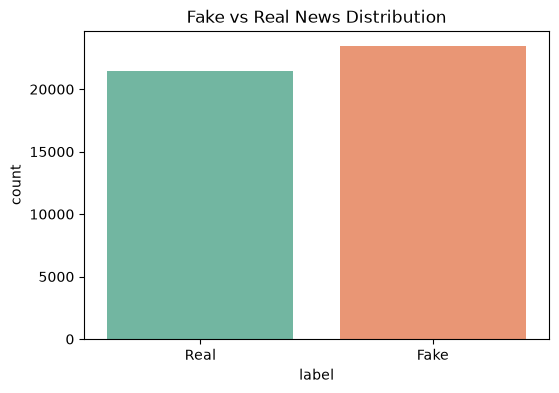

In [28]:
plt.figure(figsize=(6,4))
sns.countplot(x='label', data=df, palette='Set2')
plt.xticks([0,1], ['Real', 'Fake'])
plt.title("Fake vs Real News Distribution")
plt.show()

Checking word count distribution across Fake and Real articles

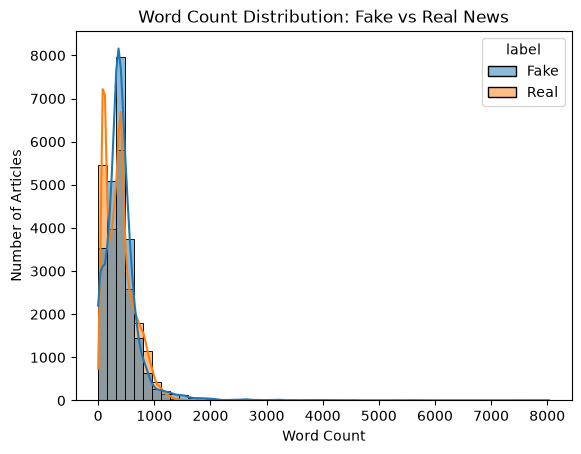

In [29]:
df['word_count'] = df['content'].apply(lambda x: len(x.split()))

sns.histplot(
    data=df,
    x='word_count',
    hue=df['label'].map({0: 'Real', 1: 'Fake'}),
    bins=50,
    kde=True,
    alpha=0.5
)

plt.title("Word Count Distribution: Fake vs Real News")
plt.xlabel("Word Count")
plt.ylabel("Number of Articles")
plt.show()

Most frequent words:

In [30]:
from collections import Counter
from wordcloud import WordCloud

fake_news = " ".join(df[df['label'] ==0]['content'])
real_news = " ".join(df[df['label']==1]['content'])

fake_words = Counter(fake_news.split()).most_common(20)
real_words = Counter(real_news.split()).most_common(20)

# Convert to DataFrame for plotting
fake_df_wc = pd.DataFrame(fake_words, columns=['word','count'])
real_df_wc = pd.DataFrame(real_words, columns=['word','count'])

Fake news frequent words: 

In [31]:
fake_df_wc.head()

,word,count
0,the,478790
1,to,252510
2,of,207863
3,a,197318
4,in,184661


Real article frequent words:

In [32]:
real_df_wc.head()

,word,count
0,the,532609
1,to,299003
2,of,240873
3,and,227807
4,a,213808


Top words in a bar plot:

C:\Users\wiggi\AppData\Local\Temp\ipykernel_13628\2133207661.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="count", y="word", data=fake_df_wc, ax=axes[1], palette="Reds")
C:\Users\wiggi\AppData\Local\Temp\ipykernel_13628\2133207661.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="count", y="word", data=real_df_wc, ax=axes[0], palette="Greens")


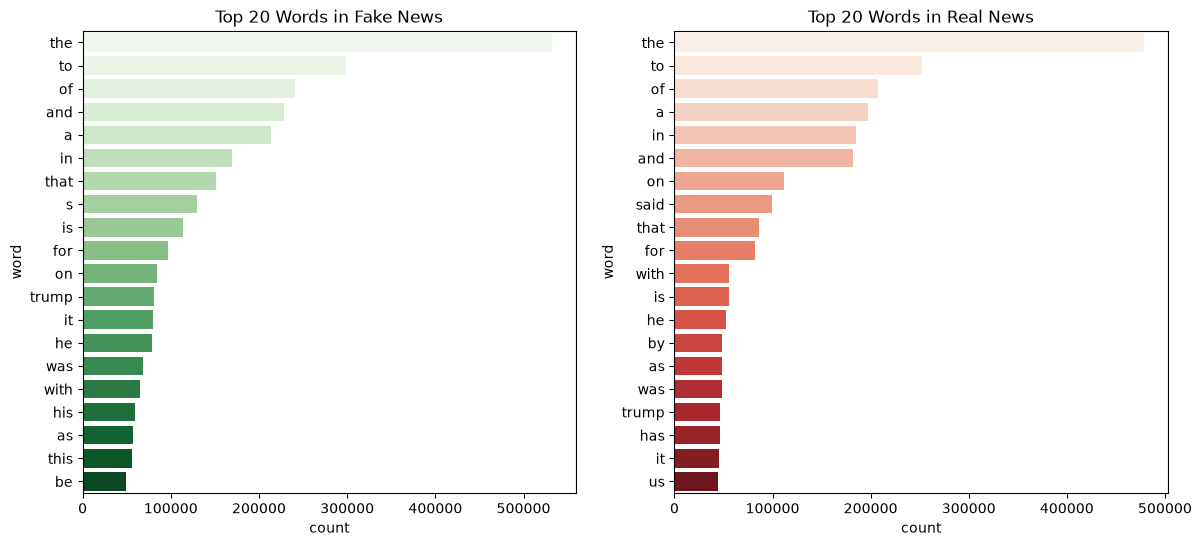

In [33]:
fig, axes = plt.subplots(1,2, figsize=(14,6))
sns.barplot(x="count", y="word", data=fake_df_wc, ax=axes[1], palette="Reds")
axes[0].set_title("Top 20 Words in Fake News")
sns.barplot(x="count", y="word", data=real_df_wc, ax=axes[0], palette="Greens")
axes[1].set_title("Top 20 Words in Real News")
plt.show()

Removing stop words so we can get more information from the top frequent words

In [34]:
import nltk
from nltk.corpus import stopwords
from collections import Counter

nltk.download('stopwords')

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\wiggi\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

Use the NLTK stop words to then cross reference them from the text and remove them. This is preprocessing the data

In [35]:
stop_words = set(stopwords.words('english'))

def preprocess_text(text):
    text = text.lower()
    words = [word for word in text.split() if word.isalpha()]
    filtered_words = [word for word in words if word not in stop_words]
    return " ".join(filtered_words)

fake_news = " ".join(df[df['label']==1]['content'])
real_news = " ".join(df[df['label']==0]['content'])

processed_fake_news = preprocess_text(fake_news)
processed_real_news = preprocess_text(real_news)

fake_words = Counter(processed_fake_news.split()).most_common(20)
real_words = Counter(processed_real_news.split()).most_common(20)

print("Top 20 words in fake news (after removing stop words):")
print(fake_words)
print("\nTop 20 words in real news (after removing stop words):")
print(real_words)

Top 20 words in fake news (after removing stop words):
[('trump', 80470), ('said', 31201), ('president', 26520), ('people', 26369), ('would', 23664), ('one', 23418), ('us', 23013), ('obama', 19513), ('clinton', 18899), ('like', 17966), ('donald', 17920), ('video', 16121), ('also', 15247), ('hillary', 15219), ('new', 15006), ('news', 14834), ('even', 13832), ('white', 13519), ('time', 12949), ('state', 12900)]

Top 20 words in real news (after removing stop words):
[('said', 99031), ('trump', 46794), ('us', 44873), ('would', 31648), ('reuters', 28365), ('president', 25683), ('state', 19171), ('government', 18257), ('house', 17730), ('new', 17587), ('states', 16243), ('also', 15946), ('republican', 15904), ('united', 15616), ('people', 14699), ('told', 14284), ('could', 13878), ('last', 12655), ('one', 12405), ('washington', 12208)]


Plot the new top 20 words:

C:\Users\wiggi\AppData\Local\Temp\ipykernel_13628\3312291260.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="count", y="word", data=fake_df_wc, ax=axes[1], palette="Reds")
C:\Users\wiggi\AppData\Local\Temp\ipykernel_13628\3312291260.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="count", y="word", data=real_df_wc, ax=axes[0], palette="Greens")


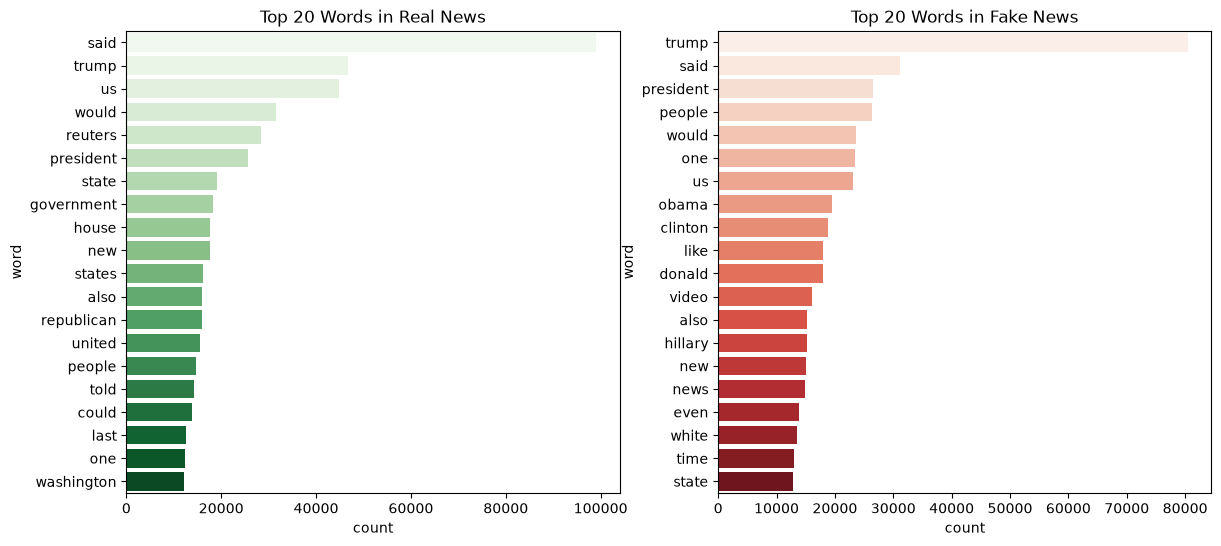

In [36]:
fake_df_wc = pd.DataFrame(fake_words, columns=['word', 'count'])
real_df_wc = pd.DataFrame(real_words, columns=['word', 'count'])

fig, axes = plt.subplots(1,2, figsize=(14,6))
sns.barplot(x="count", y="word", data=fake_df_wc, ax=axes[1], palette="Reds")
axes[1].set_title("Top 20 Words in Fake News")
sns.barplot(x="count", y="word", data=real_df_wc, ax=axes[0], palette="Greens")
axes[0].set_title("Top 20 Words in Real News")
plt.show()

Time Series Data Exploration:

In [37]:
# Convert dates to datetime; unparseable dates become NaT
df['date'] = pd.to_datetime(df['date'], errors='coerce', format='mixed')

# Check how many dates were successfully parsed
print("Total articles:", len(df))
print("Valid dates:", df['date'].notna().sum())
print("Invalid dates:", df['date'].isna().sum())

# Remove rows without usable dates for time-series analysis
ts_df = df.dropna(subset=['date']).copy()

# Sort articles chronologically
ts_df = ts_df.sort_values('date')

print(ts_df[['date', 'label']].head())

Total articles: 44898
Valid dates: 44888
Invalid dates: 10
            date  label
15885 2015-03-31      1
15890 2015-03-31      1
15889 2015-03-31      1
15888 2015-03-31      1
15887 2015-03-31      1


Analyze Monthly Trends in Data:

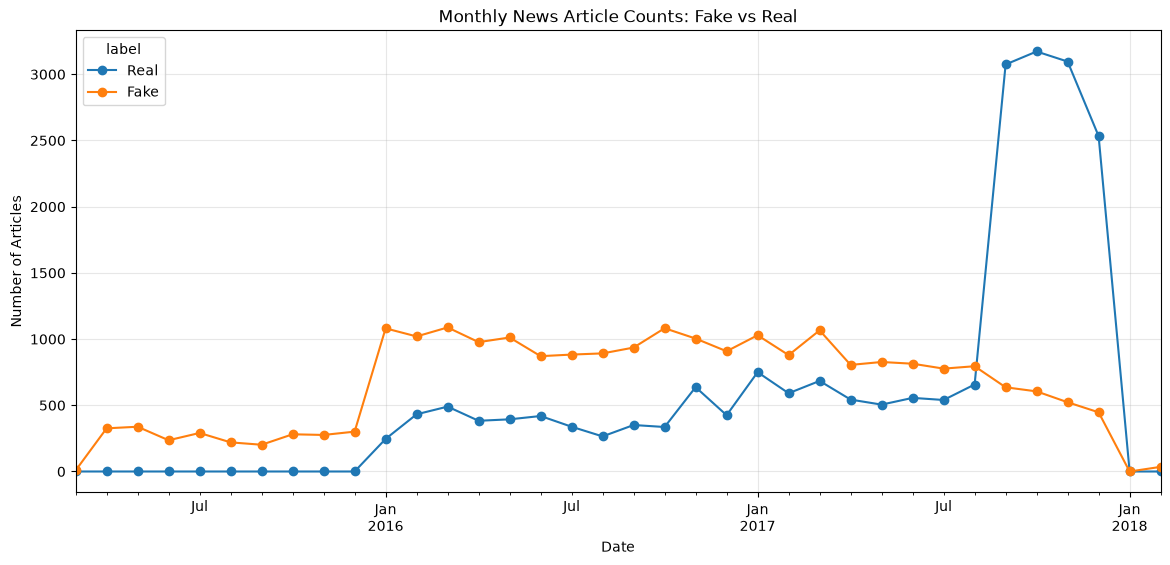

In [38]:
# Count articles published each month, separately by class
monthly = (
    ts_df.set_index('date')
    .groupby('label')
    .resample('MS')
    .size()
    .unstack(level=0, fill_value=0)
)

# Rename columns if labels are numeric: 0 = Real, 1 = Fake
monthly = monthly.rename(columns={0: 'Real', 1: 'Fake'})

monthly.plot(figsize=(14, 6), marker='o')

plt.title('Monthly News Article Counts: Fake vs Real')
plt.xlabel('Date')
plt.ylabel('Number of Articles')
plt.grid(alpha=0.3)
plt.show()

Mean, Variance, and Descriptive Statistics:

In [39]:
print("Monthly mean:")
print(monthly.mean())

print("\nMonthly variance:")
print(monthly.var())

print("\nMonthly standard deviation:")
print(monthly.std())

print("\nFull descriptive statistics:")
print(monthly.describe())

Monthly mean:
label
Real    594.916667
Fake    651.972222
dtype: float64

Monthly variance:
label
Real    791560.478571
Fake    126324.599206
dtype: float64

Monthly standard deviation:
label
Real    889.696846
Fake    355.421720
dtype: float64

Full descriptive statistics:
label         Real         Fake
count    36.000000    36.000000
mean    594.916667   651.972222
std     889.696846   355.421720
min       0.000000     0.000000
25%       0.000000   298.500000
50%     388.500000   800.000000
75%     564.750000   946.250000
max    3172.000000  1088.000000


Trend Analysis:


Real news
Slope: 50.18 articles/month
R-squared: 0.353
P-value: 0.0001


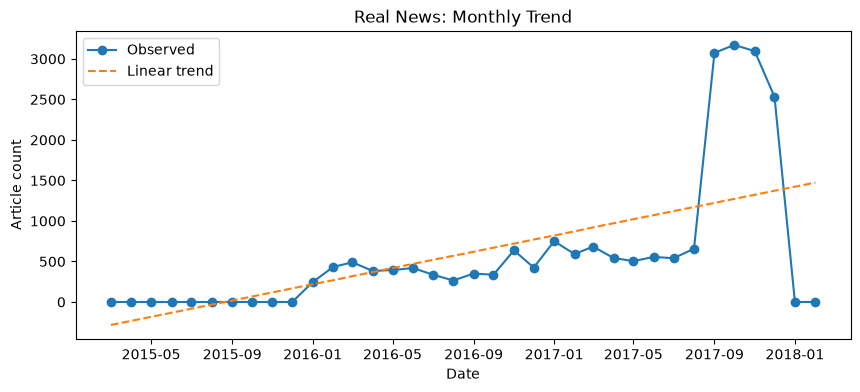


Fake news
Slope: 7.62 articles/month
R-squared: 0.051
P-value: 0.1854


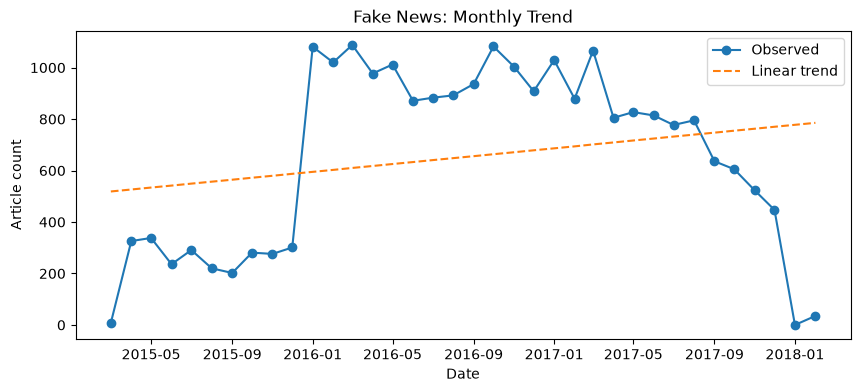

In [40]:
from scipy.stats import linregress

for col in monthly.columns:
    series = monthly[col].dropna()
    x = np.arange(len(series))
    result = linregress(x, series.values)

    print(f"\n{col} news")
    print(f"Slope: {result.slope:.2f} articles/month")
    print(f"R-squared: {result.rvalue**2:.3f}")
    print(f"P-value: {result.pvalue:.4f}")

    plt.figure(figsize=(10, 4))
    plt.plot(series.index, series.values, marker='o', label='Observed')
    plt.plot(
        series.index,
        result.intercept + result.slope * x,
        linestyle='--',
        label='Linear trend'
    )
    plt.title(f'{col} News: Monthly Trend')
    plt.xlabel('Date')
    plt.ylabel('Article count')
    plt.legend()
    plt.show()

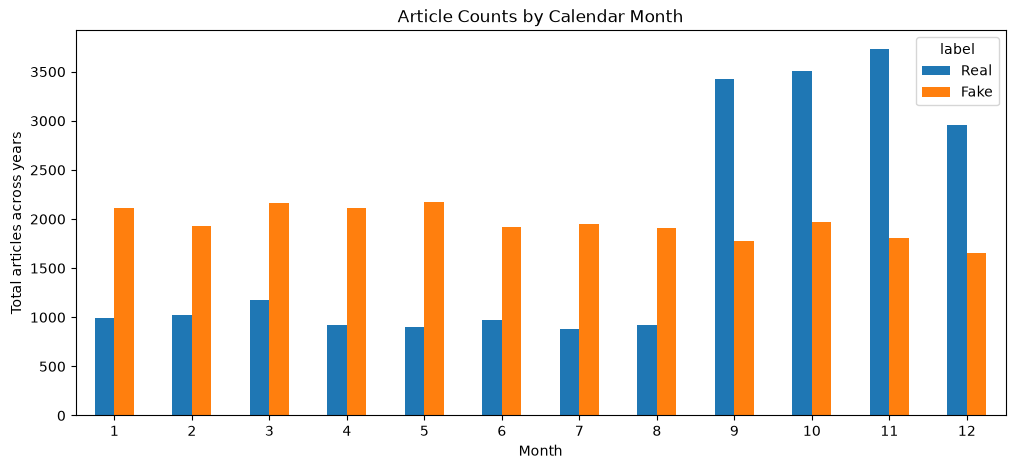

In [41]:
ts_df['month'] = ts_df['date'].dt.month

seasonality = (
    ts_df.groupby(['label', 'month'])
    .size()
    .unstack(level=0, fill_value=0)
)

seasonality = seasonality.rename(columns={0: 'Real', 1: 'Fake'})

seasonality.plot(kind='bar', figsize=(12, 5))

plt.title('Article Counts by Calendar Month')
plt.xlabel('Month')
plt.ylabel('Total articles across years')
plt.xticks(rotation=0)
plt.show()

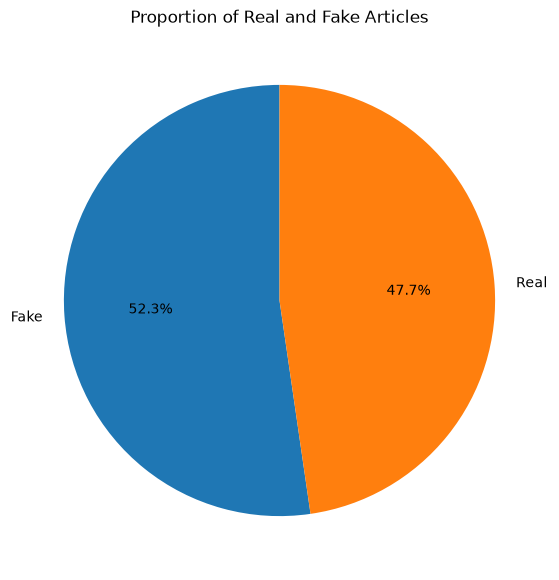

In [42]:
# Count articles in each class
label_counts = df['label'].map({
    0: 'Real',
    1: 'Fake'
}).value_counts()

# Plot pie chart
plt.figure(figsize=(7, 7))

plt.pie(
    label_counts,
    labels=label_counts.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Proportion of Real and Fake Articles')
plt.show()

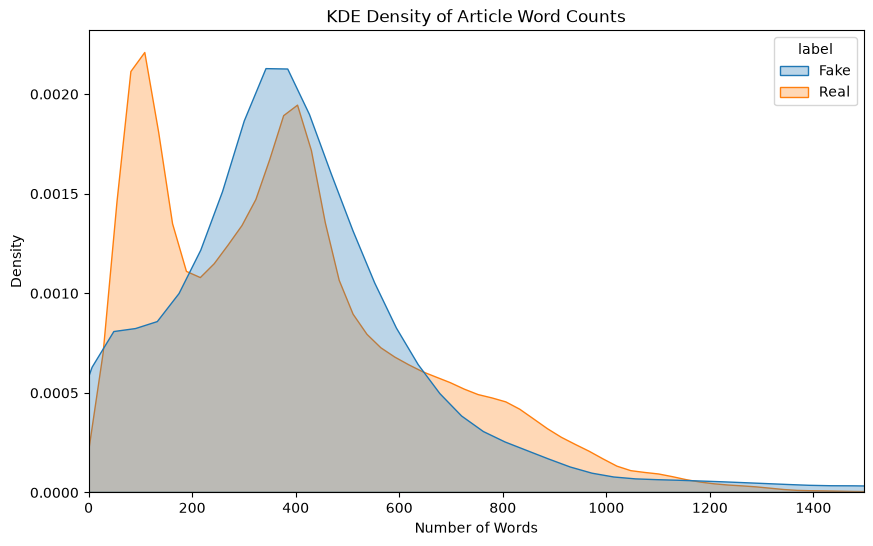

In [43]:
plt.figure(figsize=(10, 6))

sns.kdeplot(
    data=df,
    x='word_count',
    hue=df['label'].map({0: 'Real', 1: 'Fake'}),
    fill=True,
    common_norm=False,
    alpha=0.3
)

plt.title('KDE Density of Article Word Counts')
plt.xlabel('Number of Words')
plt.ylabel('Density')
plt.xlim(0, df['word_count'].quantile(0.99))

plt.show()

In [44]:
df['word_count'].describe()

count    44898.000000
mean       410.639539
std        346.024968
min          0.000000
25%        211.000000
50%        369.000000
75%        517.000000
max       8033.000000
Name: word_count, dtype: float64